In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/credit-card-customer-churn-prediction/Churn_Modelling.csv


In [ ]:
df = pd.read_csv('/kaggle/input/credit-card-customer-churn-prediction/Churn_Modelling.csv')

In [ ]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [ ]:
df.drop(columns = ['RowNumber','CustomerId','Surname'],inplace=True)

In [ ]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [ ]:
df['Geography'].value_counts()

France     5014
Germany    2509
Spain      2477
Name: Geography, dtype: int64

In [ ]:
df['Gender'].value_counts()

Male      5457
Female    4543
Name: Gender, dtype: int64

In [ ]:
df = pd.get_dummies(df,columns=['Geography','Gender'],drop_first=True)

In [ ]:
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0


In [ ]:
X = df.drop(columns=['Exited'])
y = df['Exited'].values

from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=0)

In [ ]:
X_train.shape

(8000, 11)

In [ ]:
X_test.shape

(2000, 11)

In [ ]:
y_train.shape

(8000,)

In [ ]:
y_test.shape

(2000,)

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_trf = scaler.fit_transform(X_train)
X_test_trf = scaler.transform(X_test)

In [ ]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [ ]:
model_simple = Sequential()


In [ ]:
model_simple.add(Dense(2,activation='sigmoid',input_dim=11))
model_simple.add(Dense(1,activation='sigmoid'))

In [ ]:
#build a model without Sequential
#from tensorflow.keras import Input, Model

# inputs = Input(shape=(11,))
# x = Dense(2, activation='sigmoid')(inputs)
# outputs = Dense(1, activation='sigmoid')(x)

# model = Model(inputs=inputs, outputs=outputs)

In [ ]:
model_simple.summary()

Model: "sequential_7"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense_22 (Dense)             (None, 2)                 24        
_________________________________________________________________
dense_23 (Dense)             (None, 1)                 3         
Total params: 27
Trainable params: 27
Non-trainable params: 0
_________________________________________________________________


In [ ]:
model_simple.compile(optimizer='Adam',loss='binary_crossentropy',metrics=['accuracy'])

In [ ]:
history = model_simple.fit(X_train_trf,y_train,batch_size=50,epochs=10,verbose=1,validation_split=0.2)

Epoch 1/10
128/128 [==============================] - 1s 3ms/step - loss: 0.7740 - accuracy: 0.3777 - val_loss: 0.7148 - val_accuracy: 0.4956
Epoch 2/10
128/128 [==============================] - 0s 2ms/step - loss: 0.6742 - accuracy: 0.5769 - val_loss: 0.6306 - val_accuracy: 0.6869
Epoch 3/10
128/128 [==============================] - 0s 2ms/step - loss: 0.6016 - accuracy: 0.7505 - val_loss: 0.5711 - val_accuracy: 0.7869
Epoch 4/10
128/128 [==============================] - 0s 2ms/step - loss: 0.5508 - accuracy: 0.8008 - val_loss: 0.5303 - val_accuracy: 0.8025
Epoch 5/10
128/128 [==============================] - 0s 2ms/step - loss: 0.5164 - accuracy: 0.8002 - val_loss: 0.5031 - val_accuracy: 0.7981
Epoch 6/10
128/128 [==============================] - 0s 2ms/step - loss: 0.4934 - accuracy: 0.7997 - val_loss: 0.4850 - val_accuracy: 0.7969
Epoch 7/10
128/128 [==============================] - 0s 2ms/step - loss: 0.4779 - accuracy: 0.7981 - val_loss: 0.4728 - val_accuracy: 0.7969
Epoch 

In [ ]:
model_simple.layers[0].get_weights()

[array([[ 0.1184076 , -0.14823212],
        [-0.8845439 ,  0.5473962 ],
        [ 0.03606633, -0.22950773],
        [-0.09579147,  0.5163837 ],
        [ 0.0533729 , -0.1376547 ],
        [ 0.10489716,  0.27181906],
        [ 0.3446058 , -0.8913239 ],
        [ 0.08423521,  0.2023907 ],
        [-0.70000327, -0.08995262],
        [-0.10107503, -0.21324393],
        [ 0.18918917, -0.57700664]], dtype=float32),
 array([ 0.768838  , -0.56486404], dtype=float32)]

In [ ]:
model_simple.layers[1].get_weights()

[array([[-1.4012226],
        [ 0.8037954]], dtype=float32),
 array([-0.67476285], dtype=float32)]

In [ ]:
model_simple.predict(X_train_trf)

array([[0.20812228],
       [0.27245367],
       [0.25047493],
       ...,
       [0.21483675],
       [0.15479115],
       [0.46722516]], dtype=float32)

In [ ]:
y_pred_simple = model_simple.predict(X_test_trf)

In [ ]:
y_pred_simple

array([[0.2632956 ],
       [0.3138259 ],
       [0.19118336],
       ...,
       [0.23911971],
       [0.20671603],
       [0.27163994]], dtype=float32)

In [ ]:
y_pred_simple = (y_pred_simple > 0.5).astype(int)

In [ ]:
y_pred_simple

array([[0],
       [0],
       [0],
       ...,
       [0],
       [0],
       [0]])

In [ ]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred_simple)

0.7995

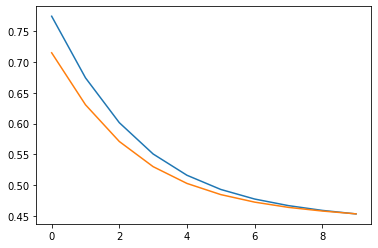

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

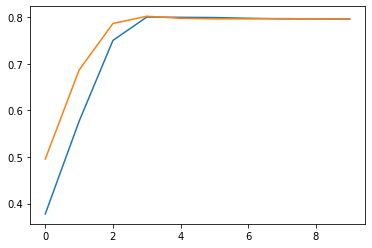

In [ ]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

Below is a more complex model

In [ ]:
model = Sequential()

model.add(Dense(10,activation='sigmoid',input_dim=11))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(1,activation='sigmoid'))

In [ ]:
model.summary()

Model: "sequential_6"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense_17 (Dense)             (None, 10)                120       
_________________________________________________________________
dense_18 (Dense)             (None, 10)                110       
_________________________________________________________________
dense_19 (Dense)             (None, 1)                 11        
Total params: 241
Trainable params: 241
Non-trainable params: 0
_________________________________________________________________


In [ ]:
model.compile(optimizer='Adam',loss='binary_crossentropy',metrics=['accuracy'])

In [ ]:
history = model.fit(X_train_trf,y_train,batch_size=50,epochs=100,verbose=1,validation_split=0.2)

Epoch 1/100
128/128 [==============================] - 1s 4ms/step - loss: 0.9055 - accuracy: 0.2347 - val_loss: 0.6818 - val_accuracy: 0.6194
Epoch 2/100
128/128 [==============================] - 0s 3ms/step - loss: 0.5929 - accuracy: 0.7819 - val_loss: 0.5325 - val_accuracy: 0.7969
Epoch 3/100
128/128 [==============================] - 0s 3ms/step - loss: 0.5106 - accuracy: 0.7958 - val_loss: 0.4941 - val_accuracy: 0.7969
Epoch 4/100
128/128 [==============================] - 0s 3ms/step - loss: 0.4880 - accuracy: 0.7958 - val_loss: 0.4817 - val_accuracy: 0.7969
Epoch 5/100
128/128 [==============================] - 0s 3ms/step - loss: 0.4788 - accuracy: 0.7958 - val_loss: 0.4751 - val_accuracy: 0.7969
Epoch 6/100
128/128 [==============================] - 0s 2ms/step - loss: 0.4724 - accuracy: 0.7958 - val_loss: 0.4696 - val_accuracy: 0.7969
Epoch 7/100
128/128 [==============================] - 0s 2ms/step - loss: 0.4665 - accuracy: 0.7958 - val_loss: 0.4643 - val_accuracy: 0.7969

In [ ]:
y_pred = model.predict(X_test_trf)

In [ ]:
y_pred

array([[0.23612559],
       [0.3171342 ],
       [0.1477432 ],
       ...,
       [0.07852206],
       [0.12965256],
       [0.2721035 ]], dtype=float32)

In [ ]:
y_pred = (y_pred > 0.5).astype(int)

In [ ]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.865

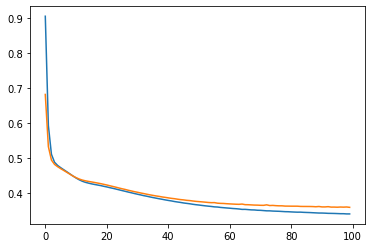

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

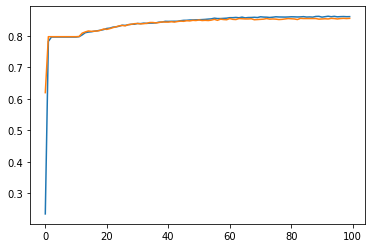

In [ ]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])